In [53]:
'''
The following code ranks the features using the built in .feature_importances_ function for forestRegressors, in a subject dependent
fashion, i.e. with subject leakage
'''
import pandas as pd
import pickle
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import os

In [54]:
def load_data(fold_num):
    return pd.read_csv(f"bcg_dataset/feat_fold_{fold_num}.csv")

In [55]:
def plot_results(results, TOP_N_FEATURES, output_folder='results'):

    os.makedirs(output_folder, exist_ok=True)
    
    print(f'\n{"="*70}')
    print('GENERATING PLOTS')
    print(f'{"="*70}')
    
    for mode in results.keys():
        fig, axes = plt.subplots(1, 2, figsize=(16, 8))
        
        # SBP plot
        sbp_top = results[mode]["SBP"].sort_values(ascending=True).tail(TOP_N_FEATURES)
        sbp_top.plot.barh(ax=axes[0], color="skyblue", edgecolor='navy', linewidth=0.5)
        axes[0].set_title(
            f'Top {TOP_N_FEATURES} Features for SBP\n'
            f'{mode.replace("_", " ").title()} CV',
            fontsize=14, fontweight='bold'
        )
        axes[0].set_xlabel('Increase in MAE', fontsize=12)
        axes[0].set_ylabel('Feature', fontsize=12)
        axes[0].axvline(x=0, color='red', linestyle='--', linewidth=1, alpha=0.7)
        axes[0].grid(axis='x', alpha=0.3)
        
        # DBP plot
        dbp_top = results[mode]["DBP"].sort_values(ascending=True).tail(TOP_N_FEATURES)
        dbp_top.plot.barh(ax=axes[1], color="lightgreen", edgecolor='darkgreen', linewidth=0.5)
        axes[1].set_title(
            f'Top {TOP_N_FEATURES} Features for DBP\n'
            f'{mode.replace("_", " ").title()} CV',
            fontsize=14, fontweight='bold'
        )
        axes[1].set_xlabel('Increase in MAE', fontsize=12)
        axes[1].set_ylabel('Feature', fontsize=12)
        axes[1].axvline(x=0, color='red', linestyle='--', linewidth=1, alpha=0.7)
        axes[1].grid(axis='x', alpha=0.3)
        
        plt.tight_layout()
        
        filename = os.path.join(output_folder, f'feature_importance_{mode}.png')
        plt.savefig(filename, dpi=300, bbox_inches='tight')
        plt.show()

Training seed 42
Training fold 1/5
Training label SP
Training label DP
Training fold 2/5
Training label SP
Training label DP
Training fold 3/5
Training label SP
Training label DP
Training fold 4/5
Training label SP
Training label DP
Training fold 5/5
Training label SP
Training label DP


Top 50 SBP Features:
AUCsys_norm: 0.1257
TdiaToEnd: 0.1170
AUCdia_norm: 0.0628
T_peak_e_norm: 0.0504
ppg_histogram_down_2: 0.0268
T_peak_a: 0.0257
SteepDiaRise: 0.0217
TNegSteepest_norm: 0.0191
vpg_max_neighbor_mean_0: 0.0172
ppg4_max_0: 0.0159
TSystoDiaRise: 0.0145
ppg3_histogram_down_8: 0.0140
usdc_2: 0.0112
T_peak_e: 0.0099
vpg_histogram_down_0: 0.0092
apg_histogram_down_3: 0.0086
TNegSteepest: 0.0083
ppg_max_neighbor_mean_0: 0.0080
ratio_apg_b: 0.0080
ppg4_min_0: 0.0077
TdiaRise: 0.0077
ppg4_histogram_down_8: 0.0073
T_b: 0.0072
Tc: 0.0070
Td: 0.0069
S4_norm: 0.0064
S3_norm: 0.0064
dsdc_18: 0.0062
sdoo: 0.0060
T_peak_b_norm: 0.0059
ratio_apg_e: 0.0057
dsdc_2: 0.0056
dsdc_12: 0.0056
dsdc_15: 0.0055
d

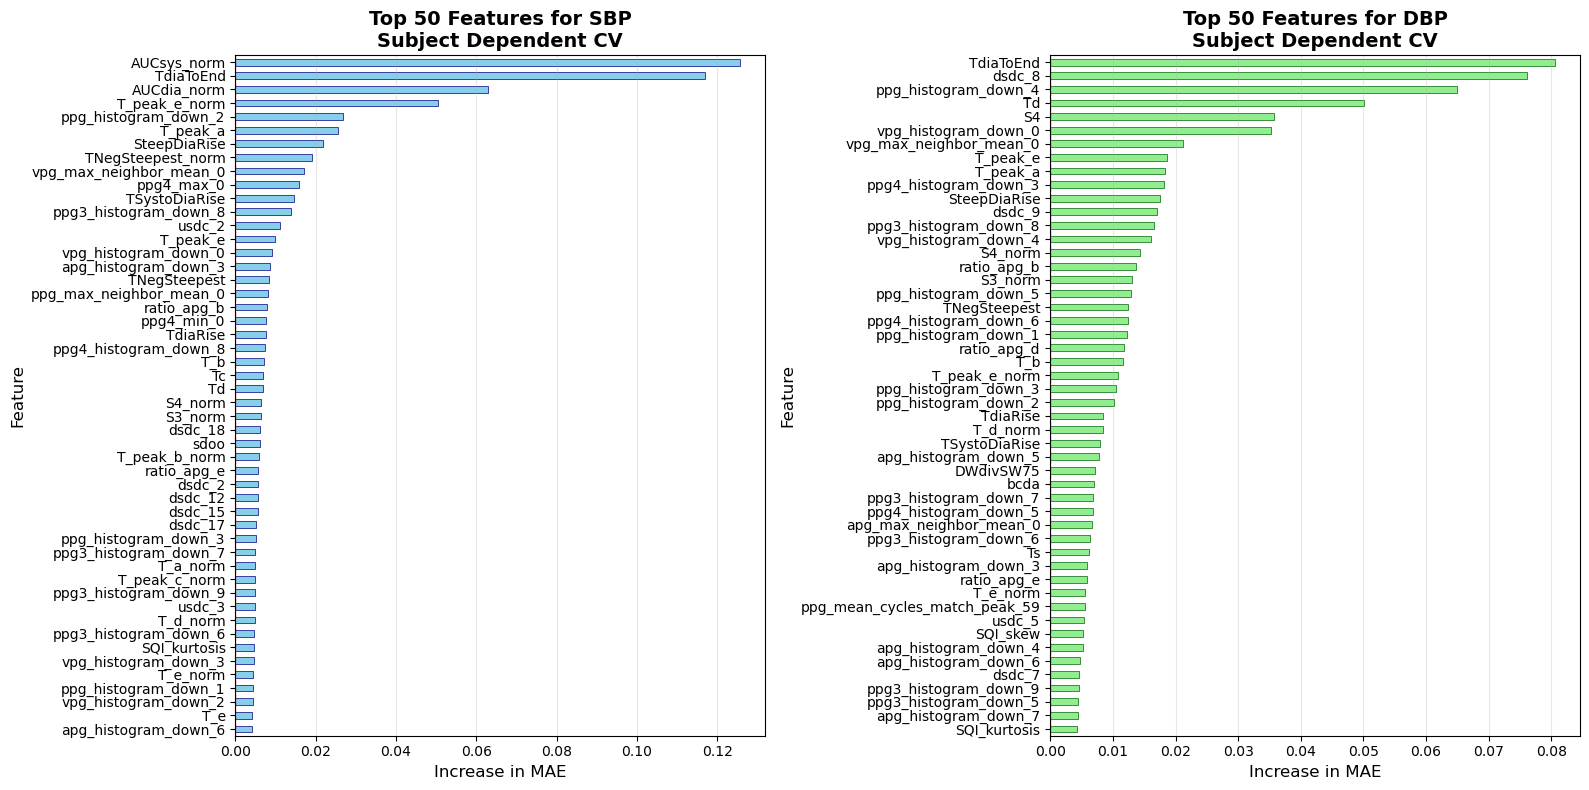

In [ ]:
folds= 5
all_maes = []
seeds = [42]
feat_imp_SBP = []
feat_imp_DBP = []
N_ESTIMATORS = 100
top_N_features = 50

for s in seeds:
    print(f'Training seed {s}')
    for fold in range(folds):
        print(f'Training fold {fold+1}/{folds}')
        test_data = load_data(fold)
        train_data = pd.concat([load_data(i) for i in range(folds) if i != fold])

        '''
        X_train_SBP, y_train_SBP = train_data.iloc[:, 4:], train_data.iloc[:,2]
        X_test_SBP, y_test_SBP = test_data.iloc[:,4:], test_data.iloc[:,2]

        X_train_DBP, y_train_DBP = train_data.iloc[:, 4:], train_data.iloc[:,3]
        X_test_DBP, y_test_DBP = test_data.iloc[:,4:], test_data.iloc[:,3]
        '''
        
        X_train = train_data.iloc[:,4:]
        X_test = test_data.iloc[:,4:]

        y_train = [
            train_data.iloc[:,2],   # SBP
            train_data.iloc[:,3]    # DBP
        ]

        y_test = [
            test_data.iloc[:,2],    # SBP
            test_data.iloc[:,3]     # DBP
        ]

        fold_maes = []
        # i = 0 for SBP training, i = 1 for DBP training
        labels = list(train_data.columns[[2,3]])
        for i in range(2):
            print(f'Training label {labels[i]}')
            rf = RandomForestRegressor(n_estimators=N_ESTIMATORS, random_state=s)
            rf.fit(X_train, y_train[i])
            y_pred = rf.predict(X_test)
            mae = np.mean(np.abs(y_test[i] - y_pred))
            fold_maes.append(mae)

            if i == 0:
                feat_imp_SBP.append(rf.feature_importances_)
            else:
                feat_imp_DBP.append(rf.feature_importances_)

# average across folds and seeds
feature_importance_SBP = np.mean(feat_imp_SBP, axis=0)
feature_importance_DBP = np.mean(feat_imp_DBP, axis=0)

feature_names = train_data.columns[4:]

sbp_ranking = sorted(
    zip(feature_names, feature_importance_SBP),
    key=lambda x: x[1],
    reverse=True
)

dbp_ranking = sorted(
    zip(feature_names, feature_importance_DBP),
    key=lambda x: x[1],
    reverse=True
)

print(f'\n\nTop {top_N_features} SBP Features:')
for name, score in sbp_ranking[:top_N_features]:
    print(f"{name}: {score:.4f}")

print(f'\n\nTop {top_N_features} DBP Features:')
for name, score in dbp_ranking[:top_N_features]:
    print(f"{name}: {score:.5f}")

sbp_series = pd.Series(feature_importance_SBP, index=feature_names)
dbp_series = pd.Series(feature_importance_DBP, index=feature_names)

results = {
    "subject_dependent": {
        "SBP": sbp_series,
        "DBP": dbp_series
    },
}

plot_results(results, TOP_N_FEATURES=top_N_features, output_folder="results_RF_importances")

# Note: feature_importance are the unsorted arrays, while s/dbp_ranking are the sorted rankings together with their corresponding importance
res = {
    "folds": folds,
    "seeds": seeds, 
    "n_estimator": N_ESTIMATORS,
    "feature_importance_SBP": feature_importance_SBP,
    "feature_importance_DBP": feature_importance_DBP,
    "sbp_ranking": sbp_ranking,
    "dbp_ranking": dbp_ranking
}

output_path = Path("results_RF_importances")
output_path.mkdir(exist_ok=True)

file_path = output_path / "rf_results.pkl"
with open(file_path, "wb") as f: 
    pickle.dump(res, f)
